# 03 – Validation with Sentinel-1
Change detection after the UN-SPIDER recommended practice: VH backscatter, orbit 136, 50 m focal-mean speckle filter, during/before ratio of the dB values > 1.25 (= darker), minus JRC permanent water and slopes > 5° (`c.sar_flood`).
Open water is a specular reflector and appears dark; the method is independent of clouds and of the optical index.

In [1]:
import ee
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

import common as c
import config as cfg

c.init()
aoi = c.study_area()
vh_during = c.sentinel1_vh_median(c.one_day(cfg.S1_DURING), aoi)

## Before image
Median of the orbit-136 images 9 May – 2 Jun 2018: snow-free, after the 2018 spring flood, crops still small (fields as in April 2019).

A single September image (6 Sep 2018) gave 1,406 km² of flood on 22 Apr and 463 km² on 20 Aug 2019 (no flood): crop growth and harvest change VH as much as water does. 20 Aug 2019 stays in the timeline as a control date.

In [2]:
vh_before = c.sentinel1_vh_median(cfg.S1_BEFORE_WINDOW, aoi)

## SAR flood over time

In [3]:
rows = []
for day in cfg.S1_TIMELINE:
    vh = c.sentinel1_vh_median(c.one_day(day), aoi)
    rows.append({"sensor": "Sentinel-1", "date": day, "flood_km2": c.area_km2(c.sar_flood(vh, vh_before), aoi)})
for day in [cfg.L8_DURING, cfg.L8_AFTER]:
    rows.append({"sensor": "Landsat 8", "date": day, "flood_km2": c.area_km2(c.optical_flood(day, aoi), aoi)})

timeline = pd.DataFrame(rows).sort_values(["sensor", "date"]).round(1)
timeline.to_csv(cfg.TABLES / "flood_area_timeline.csv", index=False)
timeline

,sensor,date,flood_km2
4,Landsat 8,2019-04-22,742.3
5,Landsat 8,2019-08-28,2.9
0,Sentinel-1,2019-04-22,566.8
1,Sentinel-1,2019-05-04,468.1
2,Sentinel-1,2019-05-16,258.6
3,Sentinel-1,2019-08-20,25.9


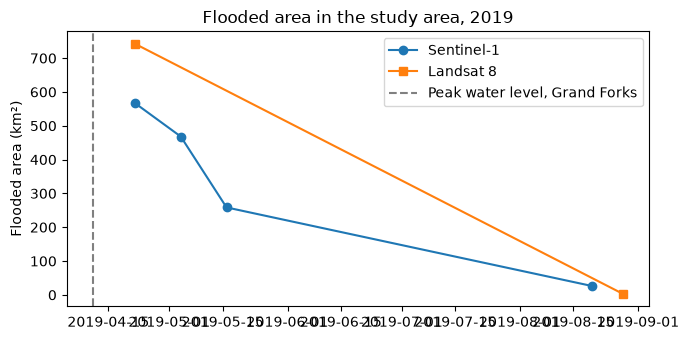

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for sensor, marker in [("Sentinel-1", "o"), ("Landsat 8", "s")]:
    rows = timeline[timeline["sensor"] == sensor]
    ax.plot(pd.to_datetime(rows["date"]), rows["flood_km2"], marker=marker, label=sensor)
ax.axvline(mdates.datestr2num(cfg.GRAND_FORKS_PEAK), color="grey", linestyle="--", label="Peak water level, Grand Forks")
ax.set_ylabel("Flooded area (km²)")
ax.set_title("Flooded area in the study area, 2019")
ax.legend()
fig.tight_layout()
fig.savefig(cfg.FIGURES / "flood_area_timeline.png", dpi=200)

## Optical vs SAR, 22 April
Sentinel-1 at 00:22 UTC, Landsat 8 at 17:21 UTC.

In [5]:
optical = c.optical_flood(cfg.L8_DURING, aoi)
radar = c.sar_flood(vh_during, vh_before)

both = optical.And(radar)
optical_only = optical.And(radar.Not())
radar_only = radar.And(optical.Not())

optical_km2 = c.area_km2(optical, aoi)
radar_km2 = c.area_km2(radar, aoi)
both_km2 = c.area_km2(both, aoi)

comparison = pd.DataFrame([
    {"layer": "optical flood (MNDWI)", "area_km2": optical_km2},
    {"layer": "SAR flood (Sentinel-1)", "area_km2": radar_km2},
    {"layer": "both", "area_km2": both_km2},
    {"layer": "optical only", "area_km2": c.area_km2(optical_only, aoi)},
    {"layer": "SAR only", "area_km2": c.area_km2(radar_only, aoi)},
]).round(1)
comparison.to_csv(cfg.TABLES / "optical_vs_sar.csv", index=False)

print(f"Areal difference SAR - optical: {radar_km2 - optical_km2:.0f} km² ({100 * (radar_km2 - optical_km2) / optical_km2:.0f} %)")
print(f"Share of the optical flood also found by SAR: {100 * both_km2 / optical_km2:.0f} %")
print(f"Share of the SAR flood also found by optical: {100 * both_km2 / radar_km2:.0f} %")
comparison

Areal difference SAR - optical: -176 km² (-24 %)
Share of the optical flood also found by SAR: 71 %
Share of the SAR flood also found by optical: 92 %


,layer,area_km2
0,optical flood (MNDWI),742.3
1,SAR flood (Sentinel-1),566.8
2,both,523.7
3,optical only,218.7
4,SAR only,39.5


## Agreement map

In [6]:
# 1 = both, 2 = optical only, 3 = SAR only
agreement = both.multiply(1).add(optical_only.multiply(2)).add(radar_only.multiply(3)).selfMask()
agreement_colors = {"min": 1, "max": 3, "palette": ["blue", "orange", "magenta"]}

m = c.Map(center=(48.5, -97.1), zoom=9)
m.addLayer(vh_before, {"min": -30, "max": -10}, "S1 VH before (May 2018 median)", False)
m.addLayer(vh_during, {"min": -30, "max": -10}, f"S1 VH {cfg.S1_DURING}")
m.addLayer(agreement, agreement_colors, "Agreement (blue both, orange optical only, magenta SAR only)")
m.add_legend(title="Flood 22 Apr", legend_dict={"both": "0000ff", "optical only": "ffa500", "SAR only": "ff00ff"})
m

Map(center=[48.5, -97.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

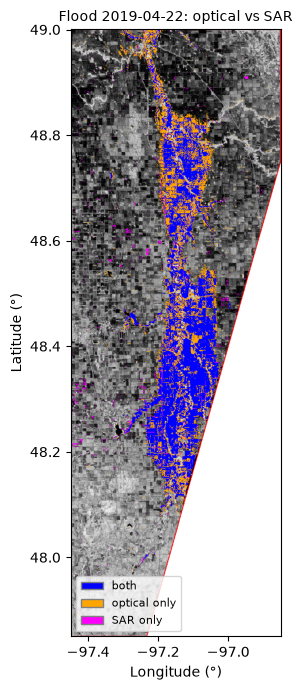

In [7]:
layer = (
    vh_during.visualize(min=-30, max=-10)
    .blend(agreement.visualize(**agreement_colors))
    .blend(c.outline(aoi))
)
fig, ax = plt.subplots(figsize=(5, 7))
c.plot_map(ax, layer, aoi, f"Flood {cfg.L8_DURING}: optical vs SAR")
ax.legend(handles=c.legend_patches({"both": "#0000ff", "optical only": "#ffa500", "SAR only": "#ff00ff"}),
          loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "agreement_map.png", dpi=200)

## JRC monthly water, April 2019
JRC GSW Monthly History (Pekel et al. 2016), built from all Landsat scenes of the month. Permanent water removed, compared only where JRC has data. Same sensor as the optical map, so not fully independent.

In [8]:
april = ee.ImageCollection(cfg.JRC_MONTHLY).filterDate("2019-04-01", "2019-05-01").first().select("water")
has_data = april.gt(0)  # 0 = no data, 1 = not water, 2 = water
jrc_flood = april.eq(2).And(c.permanent_water().Not())
jrc_km2 = c.area_km2(jrc_flood, aoi)

rows = []
for name, ours in [("optical (MNDWI)", optical), ("SAR (Sentinel-1)", radar)]:
    ours = ours.And(has_data)
    ours_km2 = c.area_km2(ours, aoi)
    both_km2 = c.area_km2(ours.And(jrc_flood), aoi)
    rows.append({
        "our map": name,
        "ours_km2": ours_km2,
        "jrc_km2": jrc_km2,
        "both_km2": both_km2,
        "ours_confirmed_by_jrc_%": 100 * both_km2 / ours_km2,
        "jrc_found_by_ours_%": 100 * both_km2 / jrc_km2,
    })
jrc_comparison = pd.DataFrame(rows).round(1)
jrc_comparison.to_csv(cfg.TABLES / "comparison_jrc_april2019.csv", index=False)
jrc_comparison

,our map,ours_km2,jrc_km2,both_km2,ours_confirmed_by_jrc_%,jrc_found_by_ours_%
0,optical (MNDWI),733.3,657.9,611.4,83.4,92.9
1,SAR (Sentinel-1),560.3,657.9,454.5,81.1,69.1


## Notes
- 22 Apr: SAR 567 km², optical 742 km² (−24 %). 71 % of the optical flood is in the SAR map, 92 % of the SAR flood in the optical map.
- SAR timeline: 567 (22 Apr) → 468 (4 May) → 259 (16 May) → 26 km² (20 Aug). Landsat 28 Aug: 3 km².
- The before image matters: 6 Sep 2018 → 1,406 km² on 22 Apr and 463 km² on the flood-free 20 Aug.
- Optical only (219 km²), possible causes: wind-roughened water, shallow water in stubble, wet soil in the before image, 17 h time difference.
- JRC April 2019: 658 km² non-permanent water. Optical: 83 % confirmed by JRC, 93 % of JRC covered. SAR: 81 % / 69 %.
- NOAA GOES-16 ABI flood product, 22 Apr (Bachmeier 2019, ~1 km): continuous band with > 80 % flood fraction, 12–15 km wide, Oslo to north of Grafton/Stephen, plus patches along the Park and Forest rivers. Same pattern as our maps at 10–30 m; the coarse product counts roads and farmyards inside the flood as flooded. The Landsat frame in the blog shows the flood continuing east of our scene edge.